In [ ]:
import pandas as pd
# fixture smoke test (runs the process on a synthetic data)
from src.fixture import make_fixture
from src.foundation import build_corpus
nodes, questions, manifest = build_corpus(make_fixture())

#### real build (writes data/interim/*.parquet + manifest)

## from the terminal run:  


## uv run --with pandas --with pyarrow --with datasets python -m src.foundation

In [55]:
docs_df = pd.read_parquet("../data/interim/nodes.parquet")

In [56]:
docs_df.head()

,node_id,title,text,freq
0,0,History of gravitational theory,"In 1687, English mathematician Sir Isaac Newto...",6
1,1,C/2014 G3,C/2014 G3 is a faint comet discovered on 10 Ap...,1
2,2,Neptune,Neptune is not visible to the unaided eye and ...,12
3,3,227 Philosophia,Philosophia (minor planet designation: 227 Phi...,1
4,4,History of science,The willingness to question previously held tr...,15


In [57]:
docs_df.shape[0]

101962

In [59]:
queries_df = pd.read_parquet("../data/interim/questions.parquet")

In [60]:
queries_df.shape[0]

22355

In [61]:
queries_df.head()

,question_id,split,query_text,n_hops,gold_node_ids,candidate_node_ids,answer
0,3hop1__614774_42467_91253,train,What is the period of revolution of the planet...,3,"[19, 11, 7]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",88 days
1,2hop__161581_53762,train,which mountain range separates kinnaur and spi...,2,"[36, 20]","[20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 3...",Himalaya mountains
2,2hop__2648_44959,train,Who did the artist Kanye profusely apologized ...,2,"[56, 58]","[40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 5...",Audrey
3,4hop1__29335_30907_482320_255237,train,What is the capital of the county containing L...,4,"[76, 69, 63, 61]","[60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 7...",Yadkinville
4,3hop1__231402_434245_87543,train,Who is the current prime minister of the count...,3,"[98, 87, 95]","[80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 9...",Haider al - Abadi


In [64]:
queries_df.value_counts("n_hops")

n_hops
2    15628
3     5147
4     1580
Name: count, dtype: int64

In [65]:
queries_df.value_counts("split")

split
train         19938
validation     2417
Name: count, dtype: int64

In [71]:
# View it as a clean dictionary
print(queries_df[queries_df["question_id"] == "2hop__381_42328"].to_dict(orient="records"))

[{'question_id': '2hop__381_42328', 'split': 'train', 'query_text': 'How many museums are there in the city where Chopin grew up?', 'n_hops': 2, 'gold_node_ids': array([8880,  743]), 'candidate_node_ids': array([  731,   741,   743,  4033,  4034,  4043,  4044,  4048,  4049,
        4051,  7285,  8880,  8881, 19574, 38979, 52801, 52802, 52803,
       52804, 52805]), 'answer': '60'}]


In [73]:
print(docs_df[docs_df["node_id"].isin([8880, 743])].to_dict(orient="records"))

[{'node_id': 743, 'title': 'Warsaw', 'text': "As interesting examples of expositions the most notable are: the world's first Museum of Posters boasting one of the largest collections of art posters in the world, Museum of Hunting and Riding and the Railway Museum. From among Warsaw's 60 museums, the most prestigious ones are National Museum with a collection of works whose origin ranges in time from antiquity till the present epoch as well as one of the best collections of paintings in the country including some paintings from Adolf Hitler's private collection, and Museum of the Polish Army whose set portrays the history of arms.", 'freq': 25}, {'node_id': 8880, 'title': 'Frédéric Chopin', 'text': 'Frédéric François Chopin (/ˈʃoʊpæn/; French pronunciation: \u200b[fʁe.de.ʁik fʁɑ̃.swa ʃɔ.pɛ̃]; 22 February or 1 March 1810 – 17 October 1849), born Fryderyk Franciszek Chopin,[n 1] was a Polish and French (by citizenship and birth of father) composer and a virtuoso pianist of the Romantic er

# EDA

Visualization successfully saved to 'musique_dataset_metrics.png'


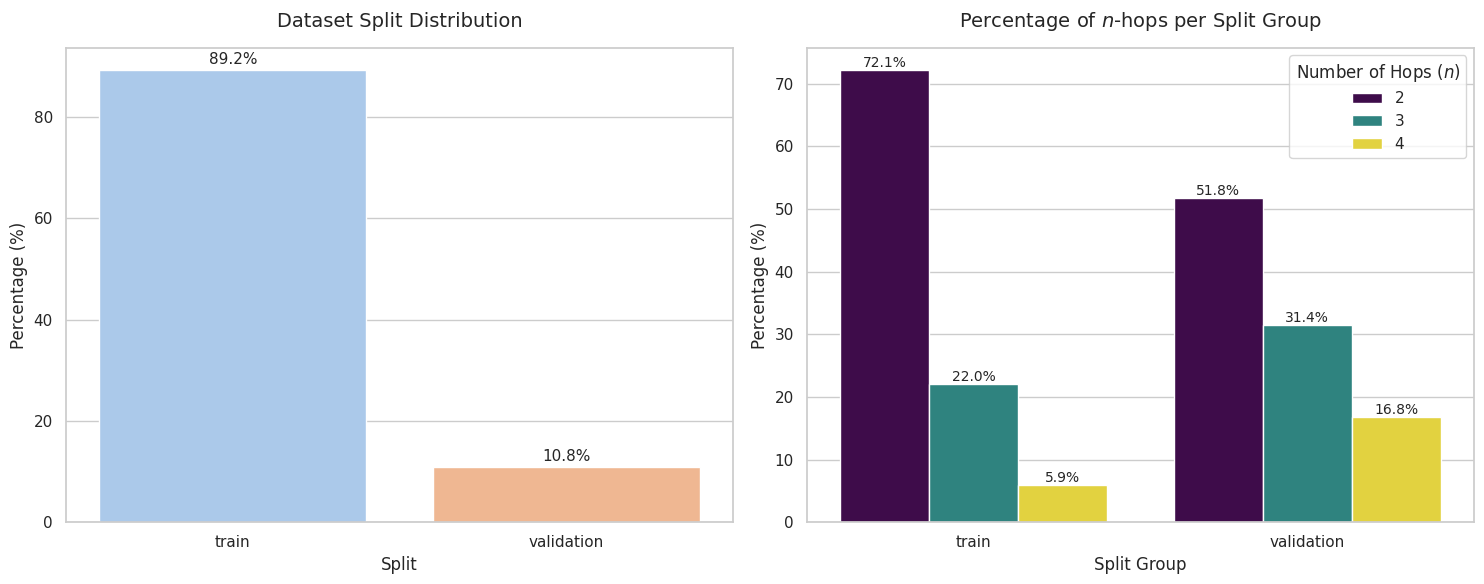

In [76]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set a clean aesthetic style
sns.set_theme(style="whitegrid")

# 1. Create a 1x2 grid of subplots (Avoiding .figure() as per guidelines)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- PLOT 1: Train vs Validation Split Percentage ---
split_counts = queries_df["split"].value_counts(normalize=True) * 100
split_data = split_counts.reset_index()
split_data.columns = ["Split Group", "Percentage"]

# Ensure bars are in sorted order
split_data = split_data.sort_values(by="Percentage", ascending=False)

sns.barplot(
    data=split_data,
    x="Split Group",
    y="Percentage",
    ax=axes[0],
    palette="pastel",
    hue="Split Group",
    legend=False,
)

axes[0].set_title("Dataset Split Distribution", fontsize=14, pad=15)
axes[0].set_ylabel("Percentage (%)", fontsize=12)
axes[0].set_xlabel("Split", fontsize=12)
axes[0].tick_params(axis="both", labelsize=11)

# Add percentage labels on top of the bars
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=11,
    )


# --- PLOT 2: n_hops Percentages per Split Group ---
# Compute the percentage of each n_hop category within each split
hop_split_pct = (
    queries_df.groupby("split")["n_hops"]
    .value_counts(normalize=True)
    .rename("Percentage")
    .reset_index()
)
hop_split_pct["Percentage"] *= 100

# Ensure the bars are plotted in a clean, sorted order by percentage
hop_split_pct = hop_split_pct.sort_values(by="Percentage", ascending=False)

sns.barplot(
    data=hop_split_pct,
    x="split",
    y="Percentage",
    hue="n_hops",
    ax=axes[1],
    palette="viridis",
)

axes[1].set_title("Percentage of $n$-hops per Split Group", fontsize=14, pad=15)
axes[1].set_ylabel("Percentage (%)", fontsize=12)
axes[1].set_xlabel("Split Group", fontsize=12)
axes[1].tick_params(axis="both", labelsize=11)
axes[1].legend(title="Number of Hops ($n$)", fontsize=11, title_fontsize=12)

# Add percentage labels on top of the grouped bars
for p in axes[1].patches:
    if p.get_height() > 0:  # Only annotate bars that have a height
        axes[1].annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="center",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=10,
        )


# 2. Adjust layout to ensure no text overlaps or gets truncated
plt.tight_layout()

# 3. Save the figure locally (Using savefig without plt.show())
print("Visualization successfully saved to 'musique_dataset_metrics.png'")

Vectorizing master document corpus...
Computing cosine similarity ranks per query...
Success! Histograms saved to 'similarity_rank_histograms.png'


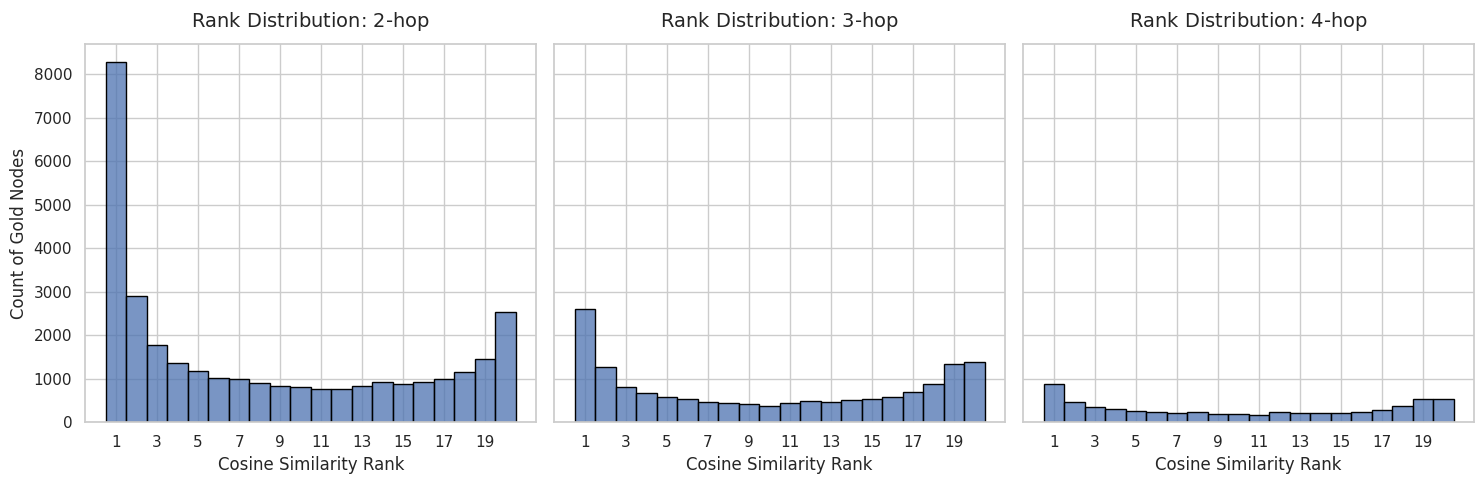

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Setup TF-IDF Vectorizer to convert text to numeric vectors
print("Vectorizing master document corpus...")
vectorizer = TfidfVectorizer(stop_words="english")

# Fit the vectorizer using the unified document text pool
X_docs = vectorizer.fit_transform(docs_df["text"])

# Create a fast lookup map: node_id -> matrix row index
node_id_to_matrix_idx = {
    node_id: idx for idx, node_id in enumerate(docs_df["node_id"])
}

# 2. Track the rank of every gold node inside its candidate pool
ranks_records = []

print("Computing cosine similarity ranks per query...")
for _, row in queries_df.iterrows():
    n_hops = row["n_hops"]
    query_text = row["query_text"]
    gold_ids = row["gold_node_ids"]
    candidate_ids = row["candidate_node_ids"]

    # Convert the single query text to a vector
    X_query = vectorizer.transform([query_text])

    # Extract matrix rows corresponding to this query's specific candidates
    cand_matrix_indices = [
        node_id_to_matrix_idx[cid]
        for cid in candidate_ids
        if cid in node_id_to_matrix_idx
    ]

    if not cand_matrix_indices:
        continue

    # Compute cosine similarity between the query vector and all its candidates
    sim_scores = cosine_similarity(X_query, X_docs[cand_matrix_indices]).flatten()

    # Create a quick dictionary mapping candidate_id to its similarity score
    cand_to_score = {cid: score for cid, score in zip(candidate_ids, sim_scores)}

    # Calculate the exact rank for each gold answer
    for gold_id in gold_ids:
        if gold_id in cand_to_score:
            gold_score = cand_to_score[gold_id]

            # Fast rank computation: 1 + count of items with strictly greater similarity
            rank = np.sum(sim_scores > gold_score) + 1

            ranks_records.append({"n_hops": n_hops, "rank": rank})

# Convert the results to a structured DataFrame
ranks_df = pd.DataFrame(ranks_records)

# 3. Plot side-by-side histograms for each n_hop category
sns.set_theme(style="whitegrid")
hop_groups = sorted(ranks_df["n_hops"].unique())

# Dynamic grid generation (Avoids .figure() constraint)
fig, axes = plt.subplots(
    1, len(hop_groups), figsize=(5 * len(hop_groups), 5), sharey=True
)

if len(hop_groups) == 1:
    axes = [axes]

for ax, hop in zip(axes, hop_groups):
    subset = ranks_df[ranks_df["n_hops"] == hop]

    # Plot histogram with discrete bins ranging from 0.5 to 20.5
    sns.histplot(
        data=subset,
        x="rank",
        bins=np.arange(0.5, 21.5, 1),
        ax=ax,
        kde=False,
        color="#4C72B0",
        edgecolor="black",
    )

    ax.set_title(f"Rank Distribution: ${hop}$-hop", fontsize=14, pad=12)
    ax.set_xlabel("Cosine Similarity Rank", fontsize=12)
    ax.set_xticks(range(1, 21, 2))
    ax.tick_params(axis="both", labelsize=11)

# Add label to the shared y-axis on the leftmost plot
axes[0].set_ylabel("Count of Gold Nodes", fontsize=12)

plt.tight_layout()
print("Success! Histograms saved to 'similarity_rank_histograms.png'")

<>:67: SyntaxWarning: invalid escape sequence '\c'
<>:67: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_237798/3556790885.py:67: SyntaxWarning: invalid escape sequence '\c'
  plt.xlabel("Cosine Similarity Score $\cos(e_{d_t}, e_q)$", fontsize=12)


Vectorizing master document corpus...
Computing cosine similarities across candidate pools...
Success! Histogram saved to 'cosine_similarity_distribution.png'


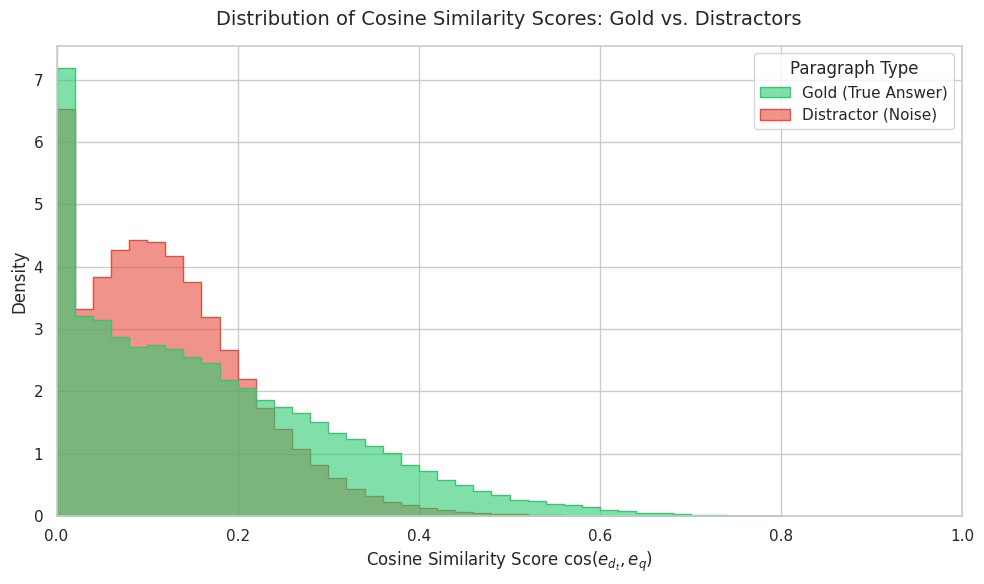

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

# 1. Setup TF-IDF Vectorizer & Map Document Indices
print("Vectorizing master document corpus...")
vectorizer = TfidfVectorizer(stop_words="english")
X_docs = vectorizer.fit_transform(docs_df["text"])

node_id_to_matrix_idx = {node_id: idx for idx, node_id in enumerate(docs_df["node_id"])}

# 2. Extract Similarity Scores for Gold vs. Distractors
gold_scores = []
distractor_scores = []

print("Computing cosine similarities across candidate pools...")
for _, row in queries_df.iterrows():
    query_text = row["query_text"]
    gold_ids = set(row["gold_node_ids"])
    candidate_ids = row["candidate_node_ids"]
    
    # Vectorize the single query
    X_query = vectorizer.transform([query_text])
    
    # Get matrix indices for this query's specific 20 candidates
    cand_matrix_indices = [node_id_to_matrix_idx[cid] for cid in candidate_ids if cid in node_id_to_matrix_idx]
    
    if not cand_matrix_indices:
        continue
        
    # Calculate similarities between query and its candidates
    sim_scores = cosine_similarity(X_query, X_docs[cand_matrix_indices]).flatten()
    
    # Separate the scores based on whether the candidate is a true gold node or a distractor
    for cid, score in zip(candidate_ids, sim_scores):
        if cid in gold_ids:
            gold_scores.append(score)
        else:
            distractor_scores.append(score)

# 3. Create a clean, combined DataFrame for plotting
df_gold = pd.DataFrame({"Cosine Similarity": gold_scores, "Paragraph Type": "Gold (True Answer)"})
df_dist = pd.DataFrame({"Cosine Similarity": distractor_scores, "Paragraph Type": "Distractor (Noise)"})
plot_df = pd.concat([df_gold, df_dist], ignore_index=True)

# 4. Plot overlapping histograms
plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df,
    x="Cosine Similarity",
    hue="Paragraph Type",
    element="step",
    stat="density",    # Normalizes because there are way more distractors than gold nodes
    common_norm=False, # Normalizes each group independently so you can compare shapes
    bins=40,
    palette={"Gold (True Answer)": "#2ecc71", "Distractor (Noise)": "#e74c3c"},
    alpha=0.6
)

plt.title("Distribution of Cosine Similarity Scores: Gold vs. Distractors", fontsize=14, pad=15)
plt.xlabel("Cosine Similarity Score $\cos(e_{d_t}, e_q)$", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, 1.0) # Similarity scales from 0 to 1

plt.tight_layout()
print("Success! Histogram saved to 'cosine_similarity_distribution.png'")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer

# 1. Load the lightweight, fast embedding model
print("Loading MiniLM model...")
model = SentenceTransformer("all-MiniLM-L6-v2")

# Create a fast global lookup index for documents: node_id -> text mapping
doc_text_lookup = dict(zip(docs_df["node_id"], docs_df["text"]))

records = []

print("Running global multi-hop diagnostic analysis...")
# We will iterate through your queries dataframe
for _, row in queries_df.iterrows():
    qid = row["question_id"]
    query_text = row["query_text"]
    gold_ids = row["gold_node_ids"]
    candidate_ids = row["candidate_node_ids"]
    n_hops = row["n_hops"]
    
    # Safety Check: Ensure all gold nodes and candidates exist in your master corpus
    if not all(gid in doc_text_lookup for gid in gold_ids) or not all(cid in doc_text_lookup for cid in candidate_ids):
        continue
        
    # Standardize candidate array order for matrix tracking
    candidate_list = list(candidate_ids)
    
    # Encode the main query and all 20 local candidate paragraphs in one single batch
    texts_to_embed = [query_text] + [doc_text_lookup[cid] for cid in candidate_list]
    embeddings = model.encode(texts_to_embed, normalize_embeddings=True)
    
    q_emb = embeddings[0]
    cand_embs = {cid: embeddings[i+1] for i, cid in enumerate(candidate_list)}
    
    # Calculate cosine similarity scores: q_emb @ cand_emb
    sims = {cid: float(q_emb @ cand_embs[cid]) for cid in candidate_list}
    
    # Rank candidates from 1 (most similar) to 20 (least similar)
    ranked_candidates = sorted(candidate_list, key=lambda cid: sims[cid], reverse=True)
    ranks = {cid: r + 1 for r, cid in enumerate(ranked_candidates)}
    
    # Loop sequentially through the true path sequence (Hops)
    for h, g_id in enumerate(gold_ids):
        prev_g_id = gold_ids[h-1] if h > 0 else None
        
        # Track metric records
        records.append({
            "qid": qid,
            "n_hops": n_hops,
            "hop": h + 1,
            "sim_query_gold": sims[g_id],
            "rank_among20": ranks[g_id],
            "sim_to_prev_gold": float(cand_embs[g_id] @ cand_embs[prev_g_id]) if prev_g_id is not None else np.nan
        })

# Build the metric DataFrame
diagnostic_df = pd.DataFrame(records)

# =====================================================================
# PRINT DIAGNOSTIC RESULTS
# =====================================================================
print("\n" + "="*50 + "\n📊 MULTI-HOP GRAPH-RL RAG DIAGNOSTICS\n" + "="*50)

# 1. The Embedding Gap: Does the similarity fade as hops go deeper?
print("\n[1] Average Cosine Similarity of True Gold Node to Main Query by Hop:")
print(diagnostic_df.groupby("hop")["sim_query_gold"].mean().to_string())

# 2. Flat Vector RAG Failure Rate: How often is a later hop buried outside the Top-5?
val_outside_top5 = (diagnostic_df.query("hop >= 2")["rank_among20"] > 5).mean() * 100
print(f"\n[2] How often a Hop >= 2 document falls OUTSIDE the Top-5: {val_outside_top5:.2f}%")

# 3. Geometric Neighbor Chain: Do consecutive gold paragraphs stay spatially close?
print("\n[3] Average Cosine Similarity Between Consecutive Gold Nodes (Bridge Strength):")
print(diagnostic_df.groupby("hop")["sim_to_prev_gold"].mean().to_string())

# =====================================================================
# RENDER VISUALIZATION HISTOGRAM
# =====================================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot overlapping distributions for each hop stage
for h, group in diagnostic_df.groupby("hop"):
    sns.histplot(
        data=group, 
        x="sim_query_gold", 
        bins=25, 
        alpha=0.5, 
        label=f"Hop {int(h)} Gold Nodes", 
        stat="density", 
        kde=True
    )

plt.title("The Spatial Decay of Multi-Hop Information Retrieval", fontsize=14, pad=15)
plt.xlabel("Cosine Similarity Score: $\cos(e_{d_t}, e_q)$", fontsize=12)
plt.ylabel("Density Proportion", fontsize=12)
plt.xlim(0, 1.0)
plt.legend(fontsize=11)
plt.tight_layout()

<>:99: SyntaxWarning: invalid escape sequence '\c'
<>:99: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_237798/1971417415.py:99: SyntaxWarning: invalid escape sequence '\c'
  plt.xlabel("Cosine Similarity Score: $\cos(e_{d_t}, e_q)$", fontsize=12)
/home/sikha/bse/rl/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
